# 2장 2강: 시계열 데이터 모델링과 예측

## 실습 목표

이번 실습에서는 **Bike Sharing Demand** 데이터를 이용하여 시계열 예측의 기본 흐름을 연습합니다.

- 시간 순서를 유지하면서 **Train / Test 데이터**를 분리합니다.
- **AR, I, MA**가 무엇을 의미하는지 확인합니다.
- **ARIMA(2, 1, 1)** 모델을 학습합니다.
- Test 기간의 미래 값을 예측합니다.
- 실제값과 예측값을 비교합니다.
- **MAE, RMSE**를 이용해 예측 성능을 평가합니다.

> 이 실습에서는 2장 2강 교안에 나온 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- statsmodels
- scikit-learn
- 데이터: `Bike_Sharing_Demand.csv`

### 주요 컬럼

| 컬럼 | 의미 |
|---|---|
| `datetime` | 자전거 대여 기록 시각 |
| `casual` | 비등록 사용자 대여 수 |
| `registered` | 등록 사용자 대여 수 |
| `count` | 전체 자전거 대여 수 |

이번 강에서는 월별 대여량 `count`를 시계열로 사용합니다.

## 실습 준비

다음 순서로 데이터를 준비합니다.

1. 데이터 불러오기
2. `datetime` 자료형 확인
3. 결측치 확인
4. `datetime`을 날짜/시간 자료형으로 변환
5. 시간 순서대로 정렬
6. 월별 대여량 `count` 준비

> 월별 집계 코드는 시계열 모델링을 위한 준비 코드로 제공됩니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bike = pd.read_csv("Bike_Sharing_Demand.csv")

print("데이터 크기:", bike.shape)
display(bike.head())

print("\n[자료형]")
display(bike[["datetime", "count"]].dtypes.to_frame("dtype"))

print("\n[결측치]")
display(bike[["datetime", "count"]].isna().sum().to_frame("missing"))

데이터 크기: (10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1



[자료형]


,dtype
datetime,str
count,int64



[결측치]


,missing
datetime,0
count,0


In [2]:
bike["datetime"] = pd.to_datetime(bike["datetime"])
bike = bike.sort_values("datetime").reset_index(drop=True)

bike["month"] = (
    bike["datetime"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly = (
    bike.groupby("month", as_index=False)["count"]
    .sum()
)

monthly = monthly.set_index("month")

print("월별 데이터 개수:", len(monthly))
display(monthly.head())
display(monthly.tail())

월별 데이터 개수: 24


,count
month,
2011-01-01,23552
2011-02-01,32844
2011-03-01,38735
2011-04-01,50517
2011-05-01,79713


,count
month,
2012-08-01,130220
2012-09-01,133425
2012-10-01,127912
2012-11-01,105551
2012-12-01,98977


---

# 필수 1. 시간 순서를 유지한 Train / Test 분리

## 배경

시계열 데이터에서는 데이터를 무작위로 섞으면 미래 시점의 데이터가 Train에 포함될 수 있습니다.

따라서 **과거 데이터를 Train**, **그 이후 데이터를 Test**로 사용해야 합니다.

이번 실습에서는 월별 대여량의 **마지막 6개월을 Test 데이터**로 사용합니다.

## 문제 1. Train / Test 데이터를 분리하세요.

### 요구사항

1. `monthly`의 마지막 6개 행을 Test 데이터로 사용합니다.
2. 나머지 데이터를 Train 데이터로 사용합니다.
3. Train과 Test의 시작일과 종료일을 출력합니다.
4. Train과 Test를 같은 그래프에 표시합니다.

### 확인 포인트

- 시간 순서를 유지했는가?
- Test 데이터가 Train 데이터보다 뒤의 기간인가?
- 무작위 분리를 사용하지 않았는가?

Train
2011-01-01 00:00:00 ~ 2012-06-01 00:00:00

Test
2012-07-01 00:00:00 ~ 2012-12-01 00:00:00


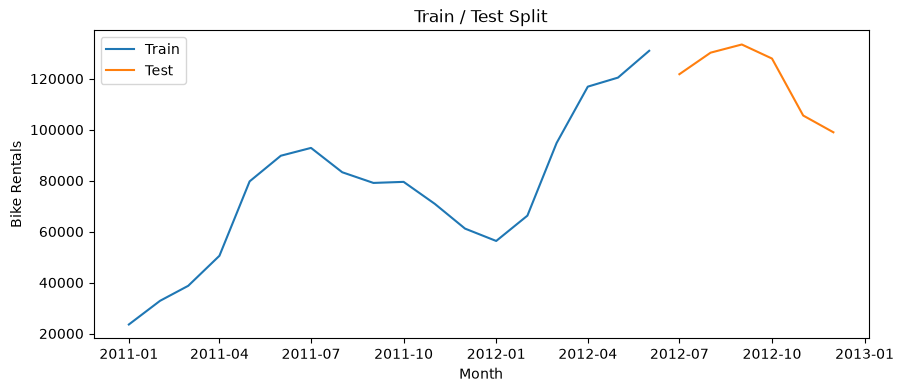

In [3]:
# TODO
# monthly 데이터를 Train / Test로 분리하세요.
train = monthly.iloc[:-6]
test = monthly.iloc[-6:]

print("Train")
print(train.index.min(), "~", train.index.max())

print("\nTest")
print(test.index.min(), "~", test.index.max())

plt.figure(figsize=(10, 4))

plt.plot(
    train.index,
    train["count"],
    label="Train")

plt.plot(
    test.index,
    test["count"],
    label="Test")

plt.xlabel("Month")
plt.ylabel("Bike Rentals")
plt.title("Train / Test Split")
plt.legend()

plt.show()

### Q1. 시계열 데이터에서 무작위로 Train / Test를 분리하면 안 되는 이유는 무엇인가요?

**답변:**  
여기에 작성하세요.


---

# 필수 2. ARIMA 모델 학습과 미래 값 예측

## 배경

ARIMA는 다음 세 가지 요소로 구성됩니다.

- **AR(p)**: 과거의 실제 값을 몇 개 사용할 것인가?
- **I(d)**: 차분을 몇 번 적용할 것인가?
- **MA(q)**: 과거의 예측 오차를 몇 개 사용할 것인가?

이번 실습에서는 교안과 동일하게 `ARIMA(2, 1, 1)`을 사용합니다.

## 문제 1. ARIMA(2, 1, 1)의 의미를 설명하세요.

### 요구사항

다음 세 값을 각각 설명합니다.

- `p = 2`
- `d = 1`
- `q = 1`

### Q2. 각각 무엇을 의미하나요?

**답변:**  
여기에 작성하세요.



## 문제 2. Train 데이터로 ARIMA 모델을 학습하세요.

### 요구사항

1. `statsmodels.tsa.arima.model`에서 `ARIMA`를 불러옵니다.
2. Train 데이터의 `count`를 사용합니다.
3. `order=(2, 1, 1)`을 지정합니다.
4. `fit()`으로 모델을 학습합니다.

### 확인 포인트

- Test 데이터를 학습에 사용하지 않았는가?
- `order=(p, d, q)`의 순서를 알고 있는가?

In [4]:
from statsmodels.tsa.arima.model import ARIMA
# TODO
# ARIMA(2, 1, 1) 모델을 생성하고 학습하세요.


## 문제 3. Test 기간만큼 미래 값을 예측하세요.

### 요구사항

1. `forecast()`를 사용합니다.
2. `steps=len(test)`로 Test 기간과 같은 개수만큼 예측합니다.
3. 예측값의 인덱스를 Test 데이터의 인덱스와 동일하게 설정합니다.
4. `actual`, `predicted` 컬럼을 가진 DataFrame을 만듭니다.
5. 실제값과 예측값을 같은 그래프에 표시합니다.

### 확인 포인트

- Train 마지막 시점 이후의 값을 예측했는가?
- Test 길이와 예측값 개수가 같은가?
- Actual과 Predicted를 구분했는가?

In [5]:
# TODO
# Test 기간만큼 예측하고 Actual / Predicted를 비교하세요.



### Q3. `steps=len(test)`는 무엇을 의미하나요?
**답변:**  
여기에 작성하세요.

---

# 과제 1. 정상성 진단을 반영한 ARIMA 예측과 예측 신뢰도 평가

## 배경

필수 1의 Train/Test 분리는 유지합니다. 과제에서는 Train 데이터의 정상성을 먼저 진단한 뒤 ARIMA의 차분 차수 d를 선택하여 모델을 다시 학습합니다. MAE·RMSE와 함께 **95% 예측 구간의 하한·상한**을 실제값과 비교합니다.

## 요구사항

1. 필수 1에서 만든 `train`, `test`를 사용합니다. 정상성 진단과 모델 설정에는 Train만 사용합니다.
2. Train의 `count`와 최근 3개 관측값의 이동평균을 그래프로 확인합니다. 원본에 ADF Test를 수행하고 검정통계량과 p-value를 출력합니다. 짧은 월별 자료이므로 이번 과제의 검정 설정은 `maxlag=1, regression="c", autolag="AIC"`로 통일합니다.
3. 유의수준 0.05에서 원본의 단위근 귀무가설을 기각하면 d=0을 우선 검토합니다. 기각하지 못하면 1차 차분한 Train에 같은 설정으로 ADF Test를 다시 수행하고 차분 그래프를 확인합니다. 차분 후 기각하면 d=1을 선택합니다. 차분 후에도 기각하지 못하면 추가 진단이 필요함을 명시하고, 이번 과제에서는 d=1을 잠정 설정하여 예측 과정과 한계를 함께 평가합니다. 선택 근거에 그래프 해석도 포함합니다.
4. **차분하지 않은 Train의 원본 `count`**를 `ARIMA(order=(2, d, 1))`에 전달해 학습합니다. 차분은 모델 내부에서 처리하므로 차분 데이터에 d=1을 다시 적용하지 않습니다. 필수 2의 모델·결과와 구분하여 과제용 변수를 사용합니다.
5. `get_forecast(steps=len(test))`로 Test 기간의 예측값과 95% 예측 구간을 구합니다. `predicted_mean`과 `conf_int(alpha=0.05)`를 활용합니다.
6. Test 날짜에 맞춰 `actual`, `predicted`, `lower_95`, `upper_95`를 가진 `task_result`를 만들고 출력합니다.
7. 과제 모델의 MAE·RMSE를 계산하고 의미를 설명합니다.
8. 실제값·예측값·95% 예측 구간을 같은 그래프에 표시합니다. 시점별 구간 폭과 실제값의 구간 포함 여부를 표에 추가하고, 구간 밖인 시점을 확인합니다.
9. 실제값과 구간의 비교 및 구간 폭을 근거로 예측 신뢰도를 해석합니다. 신뢰도가 낮다고 판단한 구간의 가능한 원인 또는 모델의 한계를 한 가지 이상 설명합니다. 구간 밖인 시점이 없더라도 구간 폭과 자료의 한계를 검토합니다.

> Test는 최종 평가에만 사용합니다. Test 결과를 보고 d나 다른 모델 설정을 다시 선택하지 않습니다. 월별 값은 제공된 CSV의 관측값 합계이며, 월 전체 날짜가 없으면 완전한 월간 총수요로 해석하지 않습니다.

### 확인 포인트

- Train만으로 정상성을 진단하고 d 선택 근거를 제시했는가?
- 1차 차분 후에도 귀무가설을 기각하지 못한 경우 잠정 모델의 한계를 밝혔는가?
- 원본 Train을 모델에 입력하여 이중 차분을 피했는가?
- MAE·RMSE와 실제값·예측값·예측 구간을 함께 확인했는가?
- 구간 밖 실제값과 구간 폭을 근거로 예측 신뢰도와 한계를 설명했는가?
- Q5~Q9에 모두 답했는가?


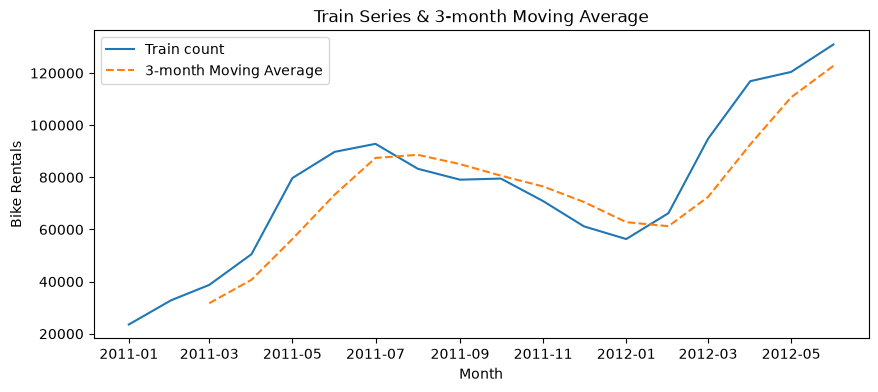

In [6]:
# TODO
# Train 정상성 진단 → d 선택 → 과제용 ARIMA 학습
# → 점예측·95% 예측 구간 → MAE·RMSE → 신뢰도 및 한계 해석

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error


# 필수1의 train 데이터
y_train = train["count"]
# 최근 3개 관측값 이동평균
ma3 = y_train.rolling(window=3).mean()

# 시각화
plt.figure(figsize=(10, 4))
plt.plot(y_train.index, y_train, label="Train count")
plt.plot(ma3.index, ma3, label="3-month Moving Average", linestyle="--")
plt.xlabel("Month")
plt.ylabel("Bike Rentals")
plt.title("Train Series & 3-month Moving Average")
plt.legend()
plt.show()


In [7]:
# 원본 ADF test
adf = adfuller(y_train, maxlag=1, regression="c", autolag="AIC")
adf_stat = adf[0]
adf_p = adf[1]
print("원본 ADF")
print("검정통계량:", round(adf_stat, 4))
print("p-value:", round(adf_p, 4))

원본 ADF
검정통계량: -1.5711
p-value: 0.4981


C:\Users\pulmo\AppData\Local\Temp\ipykernel_17448\334051796.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(y_train, maxlag=1, regression="c", autolag="AIC")


In [8]:
# 차분 차수 d 선택 
alpha = 0.05  # 유의수준 0.05
d = 0
if adf_p < alpha:
    print(f"원본 p-value={adf_p:.4f} < {alpha} → 단위근 귀무가설 기각: d=0 선택")
else:
    print(f"원본 p-value={adf_p:.4f} ≥ {alpha} → 기각 실패: 1차 차분 후 재검정")

원본 p-value=0.4981 ≥ 0.05 → 기각 실패: 1차 차분 후 재검정


1차 차분 후 ADF
검정통계량: -1.9814
p-value: 0.2948


C:\Users\pulmo\AppData\Local\Temp\ipykernel_17448\1788389014.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(train_diff, maxlag=1, regression="c", autolag="AIC")


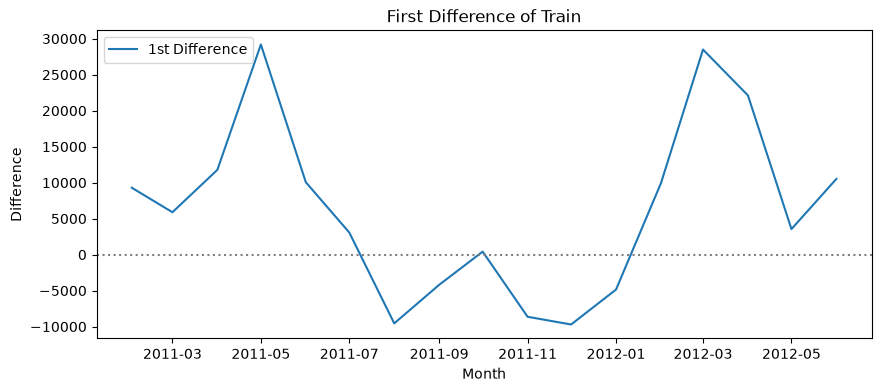

In [9]:
# 1차 차분
train_diff = y_train.diff().dropna()

# 차분 후 ADF test 재수행
adf_diff = adfuller(train_diff, maxlag=1, regression="c", autolag="AIC")
adf_diff_stat = adf_diff[0]
adf_diff_p = adf_diff[1]
print("1차 차분 후 ADF")
print("검정통계량:", round(adf_diff_stat, 4))
print("p-value:", round(adf_diff_p, 4))

# 차분 그래프 
plt.figure(figsize=(10, 4))
plt.plot(train_diff.index, train_diff, label="1st Difference")
plt.axhline(0, color="gray", linestyle=":")
plt.xlabel("Month")
plt.ylabel("Difference")
plt.title("First Difference of Train")
plt.legend()
plt.show()

In [10]:
# 차분 차수 d 재선택
d = 1
if adf_diff_p < alpha:
    print(f"차분 후 p-value={adf_diff_p:.4f} < {alpha}→ 차분 후 기각: d=1 선택")
else:
    print(f"차분 후 p-value={adf_diff_p:.4f} ≥ {alpha}→ 차분 후에도 기각 실패: 추가 진단 필요")

# 1차 차분 후에도 단위근 기각에 실패하여 추가 진단(추가 차분, 계절 차분, 표본 길이 한계 검토 등)이 필요함.
# 이번 과제에서는 d=1를 잠정 설정함. 표본이 짧아 ADF 검정력이 낮고 계절성 등이 남아 있을 수 있음.

차분 후 p-value=0.2948 ≥ 0.05→ 차분 후에도 기각 실패: 추가 진단 필요


In [11]:
# 원본 train count로 ARIMA 학습
# 차분은 모델 내부에서 처리
task_model = ARIMA(y_train, order=(2, d, 1))
task_fit = task_model.fit()
print(task_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  count   No. Observations:                   18
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -180.476
Date:                Sun, 11 Oct 2026   AIC                            368.953
Time:                        19:10:33   BIC                            372.285
Sample:                    01-01-2011   HQIC                           369.284
                         - 06-01-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5770      0.932      0.619      0.536      -1.249       2.403
ar.L2         -0.1038      0.541     -0.192      0.848      -1.165       0.957
ma.L1          0.2235      1.001      0.223      0.8

c:\practical_machine_learning_assignment_seungwon\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\practical_machine_learning_assignment_seungwon\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\practical_machine_learning_assignment_seungwon\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [12]:
# 예측값 + 95% 예측 구간
task_forecast = task_fit.get_forecast(steps=len(test))
pred_mean = task_forecast.predicted_mean
pred_ci = task_forecast.conf_int(alpha=0.05)

In [13]:
# task_result 생성
task_result = pd.DataFrame({
    "actual": test["count"].values,
    "predicted": pred_mean.values,
    "lower_95": pred_ci.iloc[:, 0].values,
    "upper_95": pred_ci.iloc[:, 1].values,
}, index=test.index)

print("task result")
display(task_result)

task result


,actual,predicted,lower_95,upper_95
month,,,,
2012-07-01,121769,139405.880749,121498.779335,157312.982163
2012-08-01,130220,143188.734859,106308.088273,180069.381446
2012-09-01,133425,144494.520944,91068.735687,197920.306200
2012-10-01,127912,144855.327175,77591.955731,212118.698619
2012-11-01,105551,144927.980297,65904.510142,223951.450453
2012-12-01,98977,144932.451482,55628.120917,234236.782048


In [14]:
# MAE, RMSE
mae = mean_absolute_error(task_result["actual"], task_result["predicted"])
rmse = np.sqrt(mean_squared_error(task_result["actual"], task_result["predicted"]))
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE : 23991.82
RMSE: 27541.81


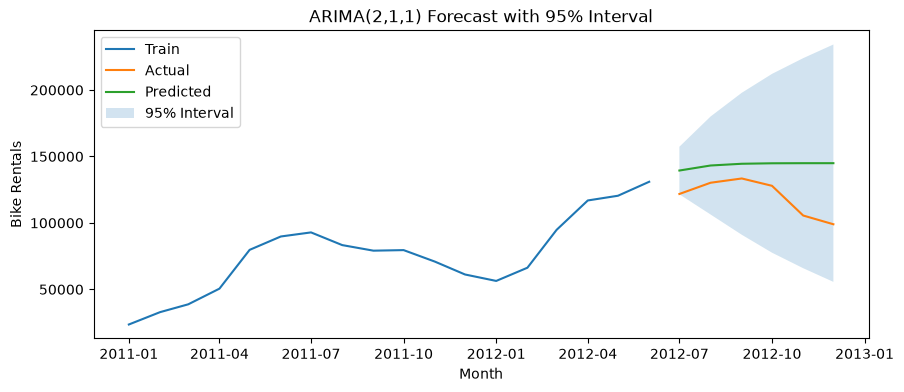

In [15]:
# 실제값,예측값,95% 예측 구간 그래프
plt.figure(figsize=(10, 4))
plt.plot(train.index, train["count"], label="Train")
plt.plot(test.index, task_result["actual"], label="Actual")
plt.plot(test.index, task_result["predicted"], label="Predicted")
plt.fill_between(test.index,
                 task_result["lower_95"],
                 task_result["upper_95"],
                 alpha=0.2, label="95% Interval")
plt.xlabel("Month")
plt.ylabel("Bike Rentals")
plt.title(f"ARIMA(2,{d},1) Forecast with 95% Interval")
plt.legend()
plt.show()

In [16]:
# 구간 폭 및 포함 여부 표
task_result["width"] = task_result["upper_95"] - task_result["lower_95"]
task_result["inside"] = (task_result["actual"] >= task_result["lower_95"]) & \
                        (task_result["actual"] <= task_result["upper_95"])
display(task_result)

print("구간 밖 시점:")
display(task_result[~task_result["inside"]])

print("구간 포함 비율:", task_result["inside"].mean())

,actual,predicted,lower_95,upper_95,width,inside
month,,,,,,
2012-07-01,121769,139405.880749,121498.779335,157312.982163,35814.202828,True
2012-08-01,130220,143188.734859,106308.088273,180069.381446,73761.293173,True
2012-09-01,133425,144494.520944,91068.735687,197920.306200,106851.570514,True
2012-10-01,127912,144855.327175,77591.955731,212118.698619,134526.742888,True
2012-11-01,105551,144927.980297,65904.510142,223951.450453,158046.940311,True
2012-12-01,98977,144932.451482,55628.120917,234236.782048,178608.661131,True


구간 밖 시점:


,actual,predicted,lower_95,upper_95,width,inside
month,,,,,,


구간 포함 비율: 1.0


### Q5. MAE는 어떻게 해석할 수 있나요?

**답변:**
월별 예측값이 실제 대여 건수와 평균적으로 몇 건 차이 나는지를 보여주는 값으로, 작을수록 좋다고 해석할 수 있다.

### Q6. RMSE가 MAE보다 큰 오차에 더 민감한 이유는 무엇인가요?

**답변:**
RMSE는 오차를 제곱해 평균한 뒤 제곱근을 취하므로 큰 오차일수록 영향이 커져 큰 오차에 더 민감하다.

### Q7. Train 데이터의 ADF 검정 결과와 그래프를 근거로 d를 어떻게 선택했나요? 정상성 판단에 남아 있는 한계는 무엇인가요?

**답변:**
원본 ADF의 p-value가 0.05 이상이어서 단위근을 기각하지 못해 1차 차분을 시행하였고 같은 설정으로 ADF 재검정후 여전히 기각되지 않아 추가 진단이 필요한 잠정 d=1로 선택하였다. 그래프상에서도 상승 추세가 발견되었다. 남아있는 한계로는 Train이 약 18개월로 짧아 ADF 검정력이 낮고, 계절성이 있어 차분만으로 정상성을 확신하기 어렵다는 점이 있다. 

### Q8. Test 실제값이 95% 예측 구간 밖에 나타난 시점은 언제이며, 구간 폭은 시점별로 어떻게 달라지나요? 이를 근거로 예측 신뢰도를 설명하세요.

**답변:**
구간 밖 시점은 없고(포함 비율 100%), 구간 폭은 7월 약 3.6만 건에서 12월 약 17.9만 건으로 약 5배 넓어진다. 평균 폭이 Test 평균 실제값의 약 96%에 달해 '모두 포함'이 곧 '정확'은 아니며, 예측 신뢰도는 낮고 특히 후반부로 갈수록 더 낮아진다.

### Q9. 예측 신뢰도가 낮다고 판단한 시점 또는 구간은 어디인가요? 가능한 원인이나 모델의 한계를 한 가지 이상 설명하세요.

**답변:**
신뢰도가 가장 낮은 구간은 2012-11~12월로 판단된다. 폭이 15.8만~17.9만 건까지 벌어졌고 예측값(약 14.5만)이 평평한 반면 실제값은 10만 근처로 하락해 실제값이 하한선에 가깝다.
ARIMA(2,1,1)가 계절성을 반영하지 못하고 마지막 상승 추세만 이어 간 것이 가능한 원인으로 추정되며 짧은 Train과 월별 값이 CSV 관측일의 합계라는 점도 한계로 볼 수 있다.


---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 시계열 Train/Test 분리에서 가장 중요한 원칙은 무엇인가요?


2. ARIMA의 `p`, `d`, `q`는 각각 무엇을 의미하나요?


3. `forecast(steps=6)`은 무엇을 의미하나요?


4. Actual과 Predicted의 차이는 무엇인가요?


